# 02 — Doped graphene in an SLG | hBN | SLG stack: model, screening, G0W self-energy, spectral function

The sample is a doped graphene sheet; a second graphene sheet (the QTM tip) sits $d=1$ nm above it,
both embedded in uniaxial hBN. Every ingredient has a closed form, so this is the benchmark of the
layer-resolved G0W chain:

$$\chi^0\ \to\ \varepsilon=1-V\chi^0\ \to\ W=\varepsilon^{-1}V\ \to\ S=-\mathrm{Im}\,W/\pi\ \to\ \Sigma(k,\varepsilon)\ \to\ A(k,\varepsilon).$$

Two cases are compared: **sample only** (tip inert, $\chi^0_{\rm tip}=0$) and **both doped**
($n_{\rm tip}=n_{\rm sample}$). Theory: `docs/notes.pdf`, Secs. 3–6.

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)

from g0w.models import dirac_chi as cd, slg_stack as ss, slg_self_energy as se
from g0w import self_energy_ppa as ppa, spectral
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

cfg_both = ss.SLGStackConfig(n_sample=0.01, n_tip=0.01, chi_on_tip=True, d_hbn=1.0, eta=1e-3)
cfg_inert = ss.SLGStackConfig(n_sample=0.01, n_tip=0.01, chi_on_tip=False, d_hbn=1.0, eta=1e-3)
cfg = cfg_both
print(f"n = {cfg.n_sample*1e14:.2e} cm^-2,  k_F = {cfg.k_F:.4f} nm^-1,  E_F = {cfg.E_F*1e3:.1f} meV,"
      f"  hbar v_F = {cfg.hv} eV nm,  eps_bar = {cfg.eps_bar:.3f}")
print(f"DOS(E_F) = {cd.dos_at_fermi(cfg.n_sample):.4f} eV^-1 nm^-2,   graphene fine structure"
      f" alpha_g = e^2/(eps_bar hbar v_F) = {1.4399764/(cfg.eps_bar*cfg.hv):.3f}")

n = 1.00e+12 cm^-2,  k_F = 0.1772 nm^-1,  E_F = 116.6 meV,  hbar v_F = 0.658 eV nm,  eps_bar = 4.385
DOS(E_F) = 0.1715 eV^-1 nm^-2,   graphene fine structure alpha_g = e^2/(eps_bar hbar v_F) = 0.499


## 1. Model: doped Dirac cone and chirality

$\xi^s_{\mathbf{k}}=s\hbar v_F|\mathbf{k}|-E_F$ ($s=\pm1$, momenta from the Dirac point), spinor
$u^s_{\mathbf{k}}=(1,se^{i\phi_{\mathbf{k}}})/\sqrt2$. The overlap that enters the self-energy is
$|\langle u^{s'}_{\mathbf{k}}|u^{s}_{\mathbf{k}-\mathbf{q}}\rangle|^2=\tfrac12[1+ss'\cos\angle(\mathbf{k},\mathbf{k}-\mathbf{q})]$:
no intraband backscattering, no interband forward scattering, and $\sum_s F^s=1$.

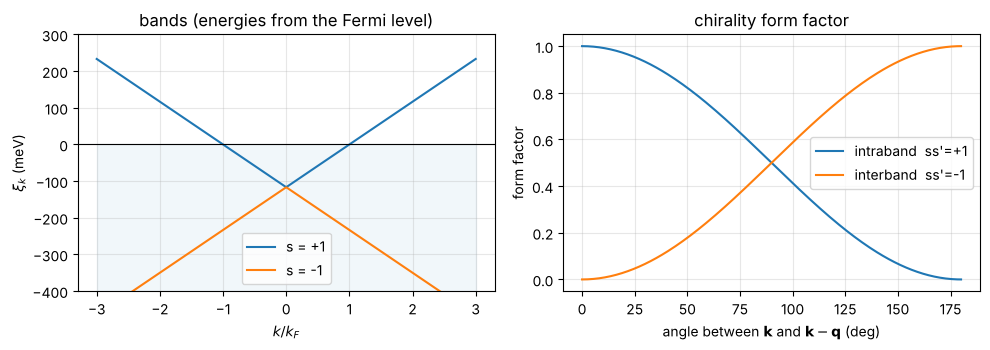

In [2]:
k = np.linspace(-3 * cfg.k_F, 3 * cfg.k_F, 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for s_ in (+1, -1):
    ax[0].plot(k / cfg.k_F, (s_ * cfg.hv * np.abs(k) - cfg.E_F) * 1e3, label=f"s = {s_:+d}")
ax[0].axhline(0, color="k", lw=0.8); ax[0].fill_between(k / cfg.k_F, -400, 0, color="C0", alpha=0.06)
ax[0].set_xlabel(r"$k/k_F$"); ax[0].set_ylabel(r"$\xi_k$ (meV)"); ax[0].set_ylim(-400, 300)
ax[0].set_title("bands (energies from the Fermi level)"); ax[0].legend()
ang = np.linspace(0, np.pi, 200)
ax[1].plot(np.degrees(ang), 0.5 * (1 + np.cos(ang)), label="intraband  ss'=+1")
ax[1].plot(np.degrees(ang), 0.5 * (1 - np.cos(ang)), label="interband  ss'=-1")
ax[1].set_xlabel(r"angle between $\mathbf{k}$ and $\mathbf{k}-\mathbf{q}$ (deg)"); ax[1].set_ylabel("form factor")
ax[1].legend(); ax[1].set_title("chirality form factor"); plt.tight_layout(); plt.show()

## 2. Polarizability $\chi^0(q,\omega)$

Closed-form $T=0$ bubble of doped graphene, analytic in the upper half plane, evaluated at $\omega+i\eta$
(`dirac_chi.chi_dirac_phys`). Checks: $\chi^0(q\to0,0)=-D(E_F)$, and agreement with a brute-force
Lindhard sum (doped minus undoped part, which is UV convergent, plus the exact undoped bubble).

w =   50 meV:  max |closed - Lindhard| / D(E_F) = 5.6e-03   (brute-force sum on a 500 x 500 polar grid)
w =  150 meV:  max |closed - Lindhard| / D(E_F) = 2.3e-03   (brute-force sum on a 500 x 500 polar grid)
chi0(q->0, 0) / (-DOS) = 1.0


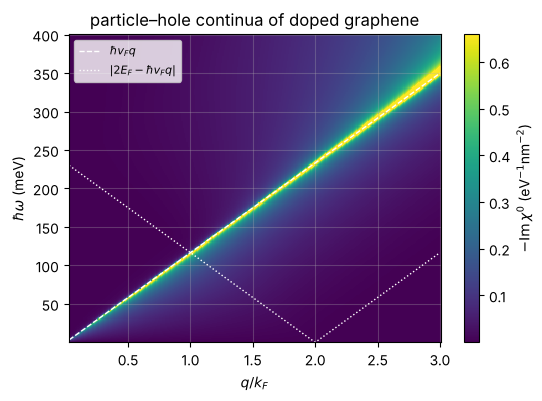

In [3]:
q_test = np.array([0.05, 0.15, 0.3])
for w_ in (0.05, 0.15):
    ref = cd.chi_dirac_lindhard_reference(w_, q_test, cfg.n_sample, eta=cfg.eta, n_k=500, n_theta=500)
    cf = cd.chi_dirac_phys(np.array([w_ + 1j * cfg.eta]), q_test, cfg.n_sample)[0]
    print(f"w = {w_*1e3:4.0f} meV:  max |closed - Lindhard| / D(E_F) = {np.max(np.abs(cf-ref))/cd.dos_at_fermi(cfg.n_sample):.1e}"
          "   (brute-force sum on a 500 x 500 polar grid)")
print("chi0(q->0, 0) / (-DOS) =", float(cd.chi_dirac_phys(np.array([1e-9]), np.array([1e-4]), cfg.n_sample)[0, 0].real
                                    / -cd.dos_at_fermi(cfg.n_sample)))

qg = np.linspace(0.005, 3 * cfg.k_F, 300); wg = np.linspace(1e-3, 0.4, 300)
chi = cd.chi_dirac_phys(wg + 1j * cfg.eta, qg, cfg.n_sample)
fig, ax = plt.subplots(figsize=(6, 4))
m = ax.pcolormesh(qg / cfg.k_F, wg * 1e3, -chi.imag, shading="auto", cmap="viridis", vmax=np.percentile(-chi.imag, 99))
up, lo = cd.ph_continuum_bounds(qg, cfg.n_sample)
ax.plot(qg / cfg.k_F, up * 1e3, "w--", lw=1, label=r"$\hbar v_F q$")
ax.plot(qg / cfg.k_F, lo * 1e3, "w:", lw=1, label=r"$|2E_F-\hbar v_F q|$")
ax.set_xlabel(r"$q/k_F$"); ax.set_ylabel(r"$\hbar\omega$ (meV)"); ax.legend(loc="upper left", fontsize=8)
plt.colorbar(m, label=r"$-\mathrm{Im}\,\chi^0$ (eV$^{-1}$nm$^{-2}$)"); ax.set_title("particle–hole continua of doped graphene")
plt.show()

## 3. Screening: $\varepsilon=1-V\chi^0$, $W=\varepsilon^{-1}V$ and the plasmons

The $2\times2$ layer problem uses $\chi^0=\mathrm{diag}(\chi_S,\chi_T)$ and the uniaxial-hBN kernel
$V_{SS}=V_{TT}=2\pi e^2/(\bar\varepsilon q)$, $V_{ST}=V_{SS}e^{-\kappa d}$. The loss $-\mathrm{Im}\,W_{SS}$
shows the collective modes; poles are found as prominent minima of $|\lambda_{\min}(\varepsilon)|$ and
their residues $R_n=\pi^{-1}\int_{\rm window}d\omega\,[-\mathrm{Im}\,W]$ define the plasmon-pole data (PPA).
With both sheets doped the single $\sqrt q$ plasmon splits into an optical (in-phase, $R_{ST}>0$)
and an acoustic (out-of-phase, $R_{ST}<0$) branch.

eps, W and plasmon poles on 144 x 480 (q, w) points: 109.4 s
acoustic branch: v_ac / v_F = 1.048  (rigorous bound: > 1)
fraction of q points with no pole at all (weight entirely in the continuum): 0.53


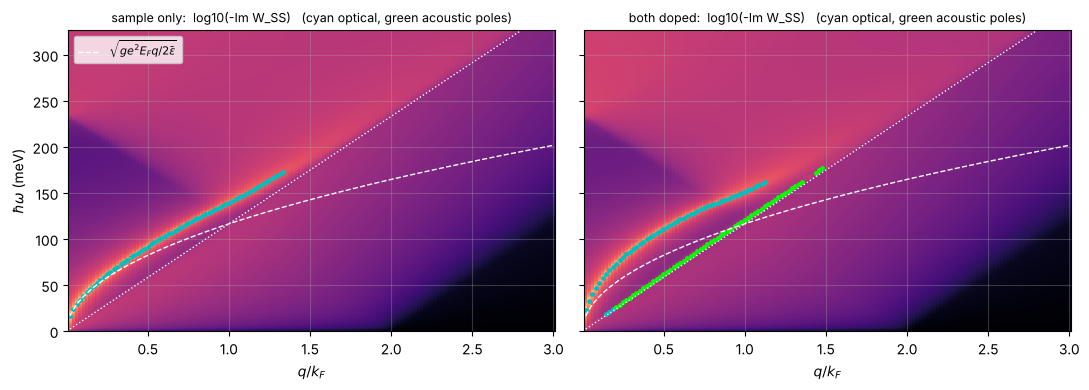

In [4]:
t0 = time.time()
n_q, n_w = 144, 480
grids = {}
for name, c in (("sample only", cfg_inert), ("both doped", cfg_both)):
    q_grid, om, ppd = ss.build_slg_ppd(c, n_q=n_q, n_omega=n_w)
    W = se.build_W_grid(c, q_grid, om)
    grids[name] = dict(q=q_grid, om=om, ppd=ppd, W=W, cfg=c)
print(f"eps, W and plasmon poles on {n_q} x {n_w} (q, w) points: {time.time()-t0:.1f} s")

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, g) in zip(axs, grids.items()):
    L = -g["W"][:, :, 0, 0].imag
    ax.pcolormesh(g["q"] / cfg.k_F, g["om"] * 1e3, np.log10(L.T + 1e-3), shading="auto", cmap="magma")
    br = ss.classify_branches(g["ppd"], g["q"], g["cfg"])
    for qi, rec in enumerate(br):
        for j in range(rec["omega"].size):
            col = "c" if rec["label"][j] == "optical" else "lime"
            ax.plot(g["q"][qi] / cfg.k_F, rec["omega"][j] * 1e3, "o", ms=2.5, color=col)
    ax.plot(g["q"] / cfg.k_F, ss.plasmon_optical_long_wavelength(g["q"], g["cfg"]) * 1e3, "w--", lw=1,
            label=r"$\sqrt{g e^2 E_F q/2\bar\varepsilon}$")
    ax.plot(g["q"] / cfg.k_F, cfg.hv * g["q"] * 1e3, "w:", lw=1)
    ax.set_title(f"{name}:  log10(-Im W_SS)   (cyan optical, green acoustic poles)", fontsize=9)
    ax.set_xlabel(r"$q/k_F$"); ax.set_ylim(0, g["om"].max() * 1e3)
axs[0].set_ylabel(r"$\hbar\omega$ (meV)"); axs[0].legend(loc="upper left", fontsize=8); plt.tight_layout(); plt.show()

g = grids["both doped"]
v_ac, _, _ = ss.acoustic_velocity_from_poles(g["ppd"], g["q"], g["cfg"], q_max_fit=cfg.k_F)
print(f"acoustic branch: v_ac / v_F = {v_ac/cfg.hv:.3f}  (rigorous bound: > 1)")
nopole = np.mean([len(w_) == 0 for w_ in g["ppd"].pole_frequencies])
print(f"fraction of q points with no pole at all (weight entirely in the continuum): {nopole:.2f}")

## 4. G0W self-energy

Full-frequency retarded correlation self-energy (Sec. 5 of the notes),

$$\Sigma_s(\mathbf{k},\varepsilon)=-\int\!\frac{q\,dq}{2\pi}\Big\langle\sum_{s'}F^{s'}(\mathbf{k},\mathbf{k}-\mathbf{q})\int_0^{\omega_{\max}}\!d\omega\,S_{SS}(q,\omega)\Big[\frac{\Theta(\xi^{s'}_{\mathbf{k}-\mathbf{q}})}{\omega+\xi^{s'}_{\mathbf{k}-\mathbf{q}}-\varepsilon-i\eta}+\frac{\Theta(-\xi^{s'}_{\mathbf{k}-\mathbf{q}})}{-\omega+\xi^{s'}_{\mathbf{k}-\mathbf{q}}-\varepsilon-i\eta}\Big]\Big\rangle_\theta,$$

with $S=-\mathrm{Im}\,W/\pi$ and $\langle\cdot\rangle_\theta$ the average over the direction of $\mathbf{q}$ (64 points).
The fast route tabulates the frequency integrals once per $q$ (`ResolventKernel`) and is checked against the
direct contraction. The PPA keeps only the pole part of $S$.

sample only: kernel tabulated in 1.4 s (18668 u points)
both doped: kernel tabulated in 1.4 s (18668 u points)
kernel route 1.10 s, direct route 78.2 s, max rel. difference 1.3e-04
passive (Im Sigma <= 0): True True


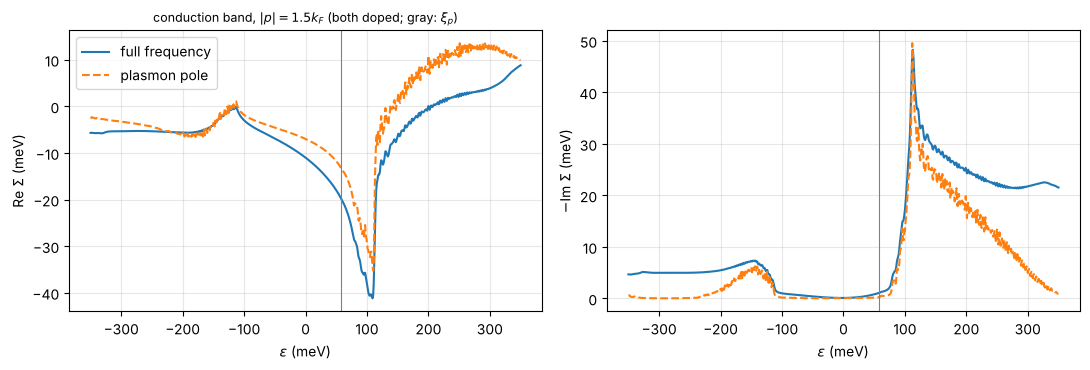

In [5]:
eps_v = np.linspace(-0.35, 0.35, 701)
p_vec = np.array([0.0, 1.5 * cfg.k_F])               # |p| = 1.5 k_F
for name, g_ in grids.items():
    g_["qw"] = ppa.make_radial_q_weights(g_["q"])
    t0 = time.time()
    g_["kernel"] = se.build_sample_kernel(g_["cfg"], g_["om"], g_["W"], eps_v, g_["q"], eta_self=1e-3)
    print(f"{name}: kernel tabulated in {time.time()-t0:.1f} s ({g_['kernel'].u.size} u points)")
g = grids["both doped"]
# check of the fast route against the direct frequency contraction (16 angles to keep it short)
t0 = time.time(); S16k = se.sigma_full_frequency_kernel(cfg, p_vec, eps_v, g["q"], g["kernel"], g["qw"], band_ext=+1, n_theta=16)
t1 = time.time(); S16d = se.sigma_full_frequency_fast(cfg, p_vec, eps_v, g["q"], g["om"], g["W"], g["qw"], band_ext=+1, eta_self=1e-3, n_theta=16)
t2 = time.time()
print(f"kernel route {t1-t0:.2f} s, direct route {t2-t1:.1f} s, max rel. difference "
      f"{np.max(np.abs(S16k-S16d))/np.max(np.abs(S16d)):.1e}")
S_ker = se.sigma_full_frequency_kernel(cfg, p_vec, eps_v, g["q"], g["kernel"], g["qw"], band_ext=+1)   # 64 angles
S_ppa = se.sigma_ppa(g["ppd"], cfg, p_vec, eps_v, band_ext=+1)
print("passive (Im Sigma <= 0):", spectral.is_passive(S_ker[0, 0]), spectral.is_passive(S_ppa[0, 0]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for S_, lab, ls in ((S_ker, "full frequency", "-"), (S_ppa, "plasmon pole", "--")):
    ax[0].plot(eps_v * 1e3, S_[0, 0].real * 1e3, ls, label=lab)
    ax[1].plot(eps_v * 1e3, -S_[0, 0].imag * 1e3, ls, label=lab)
xi = se.quasiparticle_energy(cfg, p_vec, +1)
for a in ax: a.axvline(xi * 1e3, color="gray", lw=0.8); a.set_xlabel(r"$\varepsilon$ (meV)")
ax[0].set_ylabel(r"Re $\Sigma$ (meV)"); ax[1].set_ylabel(r"$-$Im $\Sigma$ (meV)"); ax[0].legend()
ax[0].set_title(r"conduction band, $|p|=1.5k_F$ (both doped; gray: $\xi_p$)", fontsize=9); plt.tight_layout(); plt.show()

* The small ripples above the plasmon threshold come from the discrete radial $q$ grid ($n_q=144$, $\eta_\Sigma=1$ meV);
  they shrink as $1/n_q$.
* The dip of $-\mathrm{Im}\,\Sigma$ at $\varepsilon=0$ is the Fermi-liquid suppression $\propto\varepsilon^2$ (here floored by $\eta$).
* The ridges at $|\varepsilon|\gtrsim\omega_{\rm pl}$ are the plasmon-emission thresholds; they produce the satellites below.
* The PPA misses the continuum weight above $q\sim k_F$, where the plasmon has entered the interband continuum:
  it is kept only as a diagnostic, the production route is the full-frequency one.

## 5. Spectral function $A(\mathbf{k},\varepsilon)$

$A_s(\mathbf{k},\varepsilon)=-\pi^{-1}\mathrm{Im}[\varepsilon-\xi^s_{\mathbf{k}}-\Sigma_s(\mathbf{k},\varepsilon)+i\eta_{\rm qp}]^{-1}$
with an extrinsic width $\eta_{\rm qp}=2$ meV. The quasiparticle peak sits at the root of
$\varepsilon-\xi-\mathrm{Re}\,\Sigma(\varepsilon)=0$, not at $\xi$; the weight $1-Z$ moves into the satellite.

v*/v_F = 0.924,  Z in [0.820, 0.831]
(correlation part only: the Fock term, which enhances v_F in graphene, is not included -- notes Sec. 5.5)
spectral weight inside the ±350 meV window at |p| = 1.33 k_F: 0.988


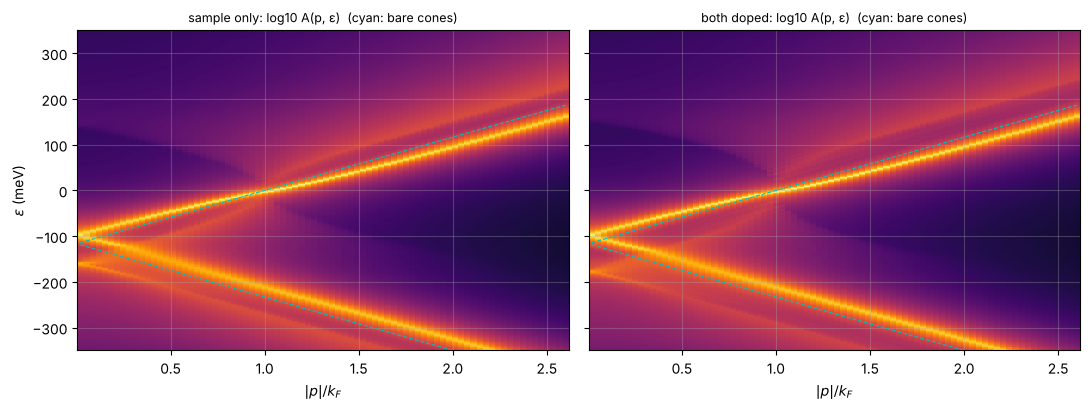

In [6]:
p_list = np.linspace(0.02, 2.6, 80) * cfg.k_F
maps = {}
for name, g_ in grids.items():
    A = np.zeros((2, p_list.size, eps_v.size)); qp = np.zeros((2, p_list.size, 2))
    for ib, b in enumerate((+1, -1)):
        for ip, pp in enumerate(p_list):
            pv = np.array([0.0, pp])
            Sg = se.sigma_full_frequency_kernel(g_["cfg"], pv, eps_v, g_["q"], g_["kernel"], g_["qw"], band_ext=b)
            A[ib, ip] = se.spectral_function_sample(g_["cfg"], pv, eps_v, Sg, band_ext=b, eta_qp=2e-3)
            sol = spectral.quasiparticle_solution(eps_v, se.quasiparticle_energy(g_["cfg"], pv, b), Sg[0, 0], window=0.1)
            qp[ib, ip] = sol["E_qp"], sol["Z"]
    maps[name] = dict(A=A, qp=qp)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (name, mp) in zip(axs, maps.items()):
    ax.pcolormesh(p_list / cfg.k_F, eps_v * 1e3, np.log10(mp["A"].sum(0).T + 1e-2), shading="auto", cmap="inferno",
                  vmin=-2, vmax=2.3)
    for b in (+1, -1):
        ax.plot(p_list / cfg.k_F, (b * cfg.hv * p_list - cfg.E_F) * 1e3, "c--", lw=0.8)
    ax.set_title(f"{name}: log10 A(p, ε)  (cyan: bare cones)", fontsize=9); ax.set_xlabel(r"$|p|/k_F$")
axs[0].set_ylabel(r"$\varepsilon$ (meV)"); axs[0].set_ylim(-350, 350); plt.tight_layout(); plt.show()

# quasiparticle renormalisation from the conduction band beyond k_F
mp = maps["sample only"]; sel = p_list > 1.2 * cfg.k_F
v_star = np.polyfit(p_list[sel], mp["qp"][0, sel, 0], 1)[0]
print(f"v*/v_F = {v_star/cfg.hv:.3f},  Z in [{np.nanmin(mp['qp'][0, sel, 1]):.3f}, {np.nanmax(mp['qp'][0, sel, 1]):.3f}]")
print("(correlation part only: the Fock term, which enhances v_F in graphene, is not included -- notes Sec. 5.5)")
w_int = spectral.spectral_weight(eps_v, maps["sample only"]["A"][0, 40])
print(f"spectral weight inside the ±350 meV window at |p| = {p_list[40]/cfg.k_F:.2f} k_F: {w_int:.3f}")

## 6. Optical / acoustic channels

For two equivalent sheets $u_\pm=(1,\pm1)/\sqrt2$ diagonalise $W$ exactly, so
$S_{SS}=\tfrac12S_{++}+\tfrac12S_{--}$ and the self-energy splits additively into an in-phase (optical)
and an out-of-phase (acoustic) part. The projection is exact also where the modes are Landau damped.

additivity: 1.051636345683414e-15
acoustic share ||Sigma_ac|| / ||Sigma||: 0.03690164704093429


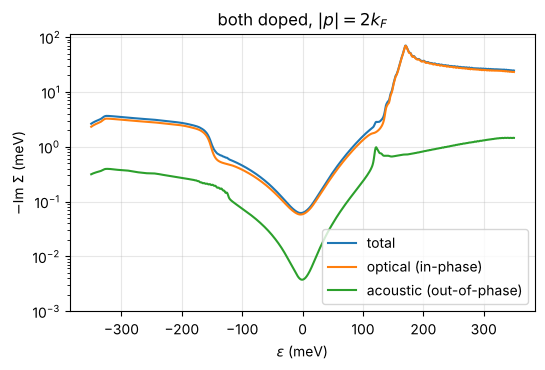

In [7]:
g = grids["both doped"]
p_vec = np.array([0.0, 2.0 * cfg.k_F])
Stot, Sop, Sac = se.sigma_full_frequency_channels_kernel(cfg, p_vec, eps_v, g["q"], g["om"], g["W"], g["qw"], eta_self=1e-3)
print("additivity:", np.max(np.abs(Sop + Sac - Stot)) / np.max(np.abs(Stot)))
print("acoustic share ||Sigma_ac|| / ||Sigma||:", np.linalg.norm(Sac[0, 0]) / np.linalg.norm(Stot[0, 0]))
plt.figure(figsize=(6, 3.6))
for S_, lab in ((Stot, "total"), (Sop, "optical (in-phase)"), (Sac, "acoustic (out-of-phase)")):
    plt.plot(eps_v * 1e3, -S_[0, 0].imag * 1e3, label=lab)
plt.yscale("log"); plt.ylim(1e-3, None); plt.xlabel(r"$\varepsilon$ (meV)"); plt.ylabel(r"$-$Im $\Sigma$ (meV)")
plt.legend(); plt.title(r"both doped, $|p|=2k_F$"); plt.show()